# Nhiệm vụ 11 V2 — Final Holdout 2024–2025

Chỉ chạy **KMeans Baseline, sklearn, K=2** đã freeze ở Nhiệm vụ 10 V2.
Development: 60 tháng 2019–2023. Holdout: 24 tháng 2024–2025; tối thiểu 100 mã/tháng.
Tham số giữ nguyên seed=42, n_init=10, max_iter=300; Robust Scaling độc lập mỗi tháng.

**Cách chạy trong VS Code:** chọn kernel Python đã dùng ở M2, Restart Kernel,
chạy các cell từ trên xuống. Hai cell code đầu chỉ kiểm tra setup và freeze gate;
cell **Bước 2** mới mở dữ liệu holdout và thực thi các bước 2–7 một lần.
Không cần đổi thư mục nếu mở từ repo hoặc `M2/notebooks`.

Đầu ra V2 riêng; không ghi đè bộ 7 tháng holdout cũ năm 2026.
Rerun chỉ kiểm chứng/nạp bộ complete, không refit. Nếu lỗi/đang chạy dở,
giữ thư mục evidence và kiểm tra nguyên nhân; không xóa rồi chạy lại để chọn kết quả.
Không quét K, không chạy Ward/PCA, không dùng holdout retune hoặc backtest.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'configs/experiments/m2_final_holdout_v2.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ repo hoặc M2/notebooks.')
sys.path.insert(0, str(ROOT / 'src'))
from delta_t1.experiments.final_holdout_v2 import freeze_gate, run_final_holdout
from delta_t1.io import read_json
pd.set_option('display.max_columns', 24)
print('Repo root:', ROOT)

Repo root: C:\Users\HOME\Desktop\M2_v1\Risk-Adjusted-Momentum-Clustering-m2-clustering-experiment


## Bước 1 — Kiểm định cổng đóng băng, chưa đọc holdout

Kiểm tra quyết định Task 10 V2, chín pinned development inputs, 60 model/checksum,
đúng sklearn/8 feature/seed/n_init/max_iter và cùng C8 V2. Nếu FAIL, dừng tại đây;
không sửa hash để bỏ qua lỗi. Bước này không tạo artifact hoặc đọc feature holdout.

In [2]:
gate = freeze_gate(ROOT)
CFG = gate['task_config']
HOLDOUT_DATES = tuple(gate['protocol']['holdout_snapshots'])
MODEL_DIR = ROOT / CFG['model_dir']
REPORT_PATH = ROOT / CFG['report_path']
display(pd.DataFrame([dict(selected_method=gate['selected_method'],
    implementation=gate['clustering']['implementation'], global_k=gate['clustering']['k'],
    k_range=gate['clustering']['k_range'], seed=gate['clustering']['seed'],
    n_init=gate['clustering']['n_init'], max_iter=gate['clustering']['max_iter'],
    development_snapshots=60, holdout_snapshots=len(HOLDOUT_DATES),
    decision_timestamp=gate['decision']['decision_timestamp'])]))
assert gate['decision']['status'] == 'FROZEN_FOR_HOLDOUT'
assert gate['clustering']['k_range'] == [2] and len(HOLDOUT_DATES) == 24
print('PASS: freeze gate. Chưa đọc feature holdout; chạy Bước 2 khi bắt đầu kiểm định.')
print('Packages:', gate['package_versions'])

,selected_method,implementation,global_k,k_range,seed,n_init,max_iter,development_snapshots,holdout_snapshots,decision_timestamp
0,KMeans_Baseline,sklearn,2,[2],42,10,300,60,24,2026-10-21T16:42:25+00:00


PASS: freeze gate. Chưa đọc feature holdout; chạy Bước 2 khi bắt đầu kiểm định.
Packages: {'numpy': '2.3.4', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}


## Bước 2 — Mở 24 snapshot và chạy duy nhất mô hình thắng

**Cell tiếp theo thực thi holdout thật.** C8 loader kiểm tra checksum rồi lấy đúng
24 tháng 2024–2025. Pipeline lọc universe, fit scaler và sklearn KMeans K=2 cho
mỗi tháng; xuất các bước 2–7. Cell có thể chạy lâu do tính metrics trên toàn bộ mã;
chờ hoàn tất. Các cell sau trình bày kết quả, không fit thêm.
Nếu đã có bộ complete, pipeline chỉ verify/nạp lại. Không sử dụng bộ holdout V1 cũ.

In [3]:
target, manifest = run_final_holdout(ROOT)
assert manifest['status'] == 'complete'
assert manifest['methods_executed'] == [gate['algorithm']]
assert manifest['k_values_executed'] == [2]
print('Artifact:', target)
print('Decision freeze:', manifest['decision_timestamp'])
print('Holdout opened:', manifest['holdout_opened_at'])
print('Feature version:', manifest['feature_version'])


Opening 24 holdout snapshots; frozen sklearn KMeans/K=2 only.
Artifact: C:\Users\HOME\Desktop\M2_v1\Risk-Adjusted-Momentum-Clustering-m2-clustering-experiment\M2\artifacts\m2-final-holdout-v2
Decision freeze: 2026-10-21T16:42:25+00:00
Holdout opened: 2026-10-21T17:31:03.218171+00:00
Feature version: 1.6.0


## Bước 3 — Universe riêng từng tháng; ngưỡng 100

Kiểm tra đủ 24 dòng snapshot validation. Tháng dưới 100 mã phải skip, ghi rõ lý do
và reset chuỗi; không nội suy/gộp ngày. Có tối đa 24 model/23 cặp; số thực tế phụ
thuộc validation, chưa được kết luận trước khi chạy.

In [4]:
validation = pd.read_csv(target / 'snapshot_validation.csv')
display(validation)
assert validation.snapshot_date.tolist() == list(HOLDOUT_DATES)
assert validation.loc[validation.status.eq('ready'), 'n_eligible'].ge(100).all()
print('Ready:', manifest['n_snapshots'], '| Skipped:', manifest['n_skipped'])

,snapshot_date,status,n_eligible,reason
0,2024-01-31,ready,959,NaN
1,2024-02-29,ready,959,NaN
2,2024-03-29,ready,960,NaN
3,2024-04-26,ready,979,NaN
4,2024-05-31,ready,997,NaN
5,2024-06-28,ready,1018,NaN
6,2024-07-31,ready,1030,NaN
7,2024-08-30,ready,1045,NaN
8,2024-09-30,ready,1054,NaN
9,2024-10-31,ready,1056,NaN


Ready: 24 | Skipped: 0


## Bước 4 — Robust Scaling độc lập

`center` là median snapshot, `scale` là IQR (scale=1 nếu IQR=0 theo preprocessing đã freeze).
Scalers nằm trong từng model JSON và bảng riêng để kiểm tra; không dùng scaler development.


In [5]:
scalers = pd.read_csv(target / 'scaler_parameters.csv')
display(scalers[['snapshot_date', 'feature', 'center', 'scale', 'method']])
assert scalers.method.eq('robust_per_snapshot').all()
assert scalers.scale.gt(0).all()
assert len(scalers) == manifest['n_snapshots'] * 8


,snapshot_date,feature,center,scale,method
0,2024-01-31,mom_21,0.000000e+00,7.959322e-02,robust_per_snapshot
1,2024-01-31,mom_63,2.857143e-02,1.533692e-01,robust_per_snapshot
2,2024-01-31,mom_126,-1.904762e-02,2.382974e-01,robust_per_snapshot
3,2024-01-31,mom_252,4.792427e-02,3.929592e-01,robust_per_snapshot
4,2024-01-31,vol_63,3.688294e-01,4.077324e-01,robust_per_snapshot
...,...,...,...,...,...
187,2025-12-31,mom_252,2.566215e-02,3.581145e-01,robust_per_snapshot
188,2025-12-31,vol_63,3.606639e-01,3.162769e-01,robust_per_snapshot
189,2025-12-31,mdd_126,-2.107564e-01,1.649419e-01,robust_per_snapshot
190,2025-12-31,beta_126,1.572477e-01,4.378657e-01,robust_per_snapshot


## Bước 5 — Assignments, profiles và model của duy nhất phương án thắng

Profiles lấy mean 8 feature gốc từ thành viên thực tế; nhãn raw khác nhãn aligned.
Model/centroid/scaler được lưu dưới `M2/models/holdout_v2/` và trong artifact.


In [6]:
assignments = pd.read_csv(target / 'assignments.csv')
profiles = pd.read_csv(target / 'cluster_profiles.csv')
display(assignments.head(12))
display(profiles)
assert not assignments.duplicated(['snapshot_date', 'security_id']).any()
assert len(assignments) == manifest['n_assignments']
counts = assignments.groupby(['snapshot_date', 'aligned_cluster_id']).size()
assert all(counts.loc[r.snapshot_date, r.aligned_cluster_id] == r.size for r in profiles.itertuples())
assert len(list(MODEL_DIR.glob('????-??-??.json'))) == manifest['n_snapshots']
print('Assignments:', len(assignments), '| Profiles:', len(profiles))

,snapshot_date,security_id,raw_cluster_id,aligned_cluster_id,run_id,data_version
0,2024-01-31,KBS:HNX:MIC,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
1,2024-01-31,KBS:HNX:PTX,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
2,2024-01-31,KBS:HOSE:AAA,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
3,2024-01-31,KBS:HOSE:AAM,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
4,2024-01-31,KBS:HOSE:ABS,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
5,2024-01-31,KBS:HOSE:ABT,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
6,2024-01-31,KBS:HOSE:ACB,1,0,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
7,2024-01-31,KBS:HOSE:ACC,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
8,2024-01-31,KBS:HOSE:ACL,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2
9,2024-01-31,KBS:HOSE:ADS,0,1,m2-final-holdout-v2,CAFEF_C8_COMPLETE_ONLY_V2


,snapshot_date,raw_cluster_id,aligned_cluster_id,size,size_ratio,mom_21,mom_63,mom_126,mom_252,vol_63,mdd_126,beta_126,liquidity_21
0,2024-01-31,0,1,930,0.969760,0.008920,0.047165,-0.012653,0.120045,0.464604,-0.260865,0.383216,4.936753e+09
1,2024-01-31,1,0,29,0.030240,0.030477,0.179136,0.072554,0.371611,0.290499,-0.266948,1.436874,3.092983e+11
2,2024-02-29,0,1,929,0.968717,0.031335,0.062926,0.015457,0.171983,0.454799,-0.245406,0.351156,5.597198e+09
3,2024-02-29,1,0,30,0.031283,0.071340,0.158069,0.120292,0.571658,0.248721,-0.260495,1.441346,3.658146e+11
4,2024-03-29,0,1,937,0.976042,0.047705,0.096748,0.075493,0.203725,0.464502,-0.215969,0.334250,9.121469e+09
5,2024-03-29,1,0,23,0.023958,0.050898,0.179405,0.172399,0.583823,0.265551,-0.189176,1.382197,5.593977e+11
6,2024-04-26,0,1,954,0.974464,-0.024037,0.044046,0.065764,0.148360,0.480440,-0.215808,0.346224,7.776887e+09
7,2024-04-26,1,0,25,0.025536,-0.078067,0.039660,0.154417,0.459896,0.327555,-0.163945,1.335380,4.673273e+11
8,2024-05-31,0,1,966,0.968907,0.064358,0.078302,0.139063,0.170035,0.511483,-0.213783,0.283094,8.036697e+09
9,2024-05-31,1,0,31,0.031093,0.076375,0.062480,0.251734,0.502966,0.330288,-0.152394,1.253995,3.775147e+11


Assignments: 28110 | Profiles: 48


## Bước 6 — Quality, temporal stability, gap và hồ sơ

Chỉ so sánh các tháng holdout liên tiếp hợp lệ. Không tính transition từ
2023-12-29 sang 2024-01-31, kể cả khi dữ liệu không có gap lịch.
ARI/NMI đo phân hoạch; Persistence/Migration trên mã chung; Entry/Exit tách riêng.
Generalization Gap = median Holdout − median Development, không dùng để retune.

In [7]:
diagnostics = pd.read_csv(target / 'diagnostics.csv')
quality = pd.read_csv(target / 'quality_summary.csv')
temporal = pd.read_csv(target / 'temporal_stability.csv')
transitions = pd.read_csv(target / 'transition_matrices.csv')
drift = pd.read_csv(target / 'centroid_drift.csv')
gap = pd.read_csv(target / 'holdout_generalization_gap.csv')
display(diagnostics)
display(quality)
display(temporal)
display(gap)
assert diagnostics.k.eq(2).all()
allowed_pairs = set(zip(HOLDOUT_DATES[:-1], HOLDOUT_DATES[1:]))
assert set(zip(temporal.from_date, temporal.to_date)) <= allowed_pairs
assert len(temporal) == manifest['n_temporal_pairs']
for r in temporal.itertuples():
    pair = transitions[transitions.from_date.eq(r.from_date) & transitions.to_date.eq(r.to_date)]
    assert pair['count'].sum() == r.n_common
    assert abs(pair.loc[pair.from_cluster.eq(pair.to_cluster), 'count'].sum() / r.n_common - r.persistence_probability) < 1e-10
assert (abs(drift.value_to-drift.value_from-drift.delta) <= (drift.value_to.abs()+drift.value_from.abs()+drift.delta.abs())*1e-12 + 1e-9).all()
profile_check = pd.read_csv(target / 'profile_consistency.csv')
display(profile_check.pivot(index=['role','feature'], columns='period', values='mean'))
sil = gap.set_index('metric').loc['silhouette']
print(f"Delta_Silhouette = {sil.holdout_median:.6f} - {sil.development_median:.6f} = {sil.delta_holdout_minus_development:+.6f}")

,snapshot_date,k,silhouette,calinski_harabasz,davies_bouldin,inertia,cluster_sizes,cluster_balance,converged
0,2024-01-31,2,0.943272,2554.284697,0.415619,1.263345e+06,"{""0"": 930, ""1"": 29}",0.031183,True
1,2024-02-29,2,0.948357,3486.581628,0.341653,1.425822e+06,"{""0"": 929, ""1"": 30}",0.032293,True
2,2024-03-29,2,0.948421,3149.370205,0.343113,1.702371e+06,"{""0"": 937, ""1"": 23}",0.024546,True
3,2024-04-26,2,0.946805,3382.467990,0.366572,1.481406e+06,"{""0"": 954, ""1"": 25}",0.026205,True
4,2024-05-31,2,0.929631,2699.563463,0.389951,8.221648e+05,"{""0"": 966, ""1"": 31}",0.032091,True
5,2024-06-28,2,0.922272,2139.897385,0.460873,4.813149e+05,"{""0"": 989, ""1"": 29}",0.029323,True
6,2024-07-31,2,0.918441,2431.158493,0.406451,5.972012e+05,"{""0"": 989, ""1"": 41}",0.041456,True
7,2024-08-30,2,0.934871,2730.807010,0.442647,1.151558e+06,"{""0"": 1011, ""1"": 34}",0.033630,True
8,2024-09-30,2,0.944607,3752.659051,0.350603,8.013523e+05,"{""0"": 1026, ""1"": 28}",0.027290,True
9,2024-10-31,2,0.949438,2925.956334,0.408338,1.340490e+06,"{""0"": 1034, ""1"": 22}",0.021277,True


,metric,n_total,n_available,mean,median,minimum,maximum
0,silhouette,24,24,9.437927e-01,9.459272e-01,0.918441,9.657536e-01
1,davies_bouldin,24,24,3.980026e-01,3.999882e-01,0.321662,4.660797e-01
2,calinski_harabasz,24,24,3.229154e+03,3.191392e+03,2139.897385,4.884205e+03
3,inertia,24,24,1.560524e+06,1.290878e+06,481314.911060,4.652228e+06
4,cluster_balance,24,24,2.516980e-02,2.494146e-02,0.017572,4.145602e-02


,from_date,to_date,n_common,ari,nmi,persistence_probability,migration_rate,entered_count,exited_count,status
0,2024-01-31,2024-02-29,958,0.944378,0.871650,0.996868,0.003132,1,1,OK
1,2024-02-29,2024-03-29,958,0.857552,0.762187,0.992693,0.007307,2,1,OK
2,2024-03-29,2024-04-26,959,0.906916,0.805661,0.995829,0.004171,20,1,OK
3,2024-04-26,2024-05-31,975,0.800820,0.656148,0.989744,0.010256,22,4,OK
4,2024-05-31,2024-06-28,996,0.891153,0.778988,0.993976,0.006024,22,1,OK
5,2024-06-28,2024-07-31,1016,0.743982,0.582556,0.984252,0.015748,14,2,OK
6,2024-07-31,2024-08-30,1029,0.722512,0.541883,0.981535,0.018465,16,1,OK
7,2024-08-30,2024-09-30,1038,0.805124,0.662841,0.989403,0.010597,16,7,OK
8,2024-09-30,2024-10-31,1053,0.829497,0.704869,0.992403,0.007597,3,1,OK
9,2024-10-31,2024-11-29,1056,0.841807,0.709854,0.993371,0.006629,193,0,OK


,metric,development_n,holdout_n,development_median,holdout_median,delta_holdout_minus_development
0,silhouette,60,24,0.931935,9.459272e-01,1.399212e-02
1,davies_bouldin,60,24,0.396416,3.999882e-01,3.572328e-03
2,calinski_harabasz,60,24,1122.325007,3.191392e+03,2.069067e+03
3,inertia,60,24,82143.837336,1.290878e+06,1.208734e+06
4,cluster_balance,60,24,0.023814,2.494146e-02,1.127939e-03
5,ari,59,23,0.768741,8.496156e-01,8.087413e-02
6,nmi,59,23,0.624996,7.237117e-01,9.871542e-02
7,persistence_probability,59,23,0.989313,9.935897e-01,4.276766e-03
8,migration_rate,59,23,0.010687,6.410256e-03,-4.276766e-03


period                      development       holdout
role         feature                                 
Higher_mom63 beta_126      1.085649e+00  8.605971e-01
             liquidity_21  1.693928e+11  3.316594e+11
             mdd_126      -2.702790e-01 -2.124144e-01
             mom_126       4.839322e-01  1.822790e-01
             mom_21        4.623896e-02  3.661723e-02
             mom_252       6.255115e-01  2.956006e-01
             mom_63        2.677790e-01  1.310484e-01
             vol_63        4.711698e-01  3.907449e-01
Lower_mom63  beta_126      6.811677e-01  7.698988e-01
             liquidity_21  8.574762e+10  1.604451e+11
             mdd_126      -2.832610e-01 -2.133406e-01
             mom_126       1.276642e-01  1.094784e-01
             mom_21        1.168306e-02  1.178285e-02
             mom_252       2.869938e-01  2.427014e-01
             mom_63        3.782912e-02  3.456026e-02
             vol_63        4.939771e-01  4.021700e-01

Delta_Silhouette = 0.945927 - 0.931935 = +0.013992


## Bước 7 — Biểu đồ 84 mốc, manifest và báo cáo

60 development + 24 holdout, hai đường median và đường đỏ ranh giới; không nối
hai chuỗi. Chạy verify-only lần nữa để xác nhận checksum và khả năng nạp lại.
Báo cáo được sinh từ số liệu thực tế, không dùng trước các kịch bản giả định.
Task 12/M3 cần được thực hiện riêng.

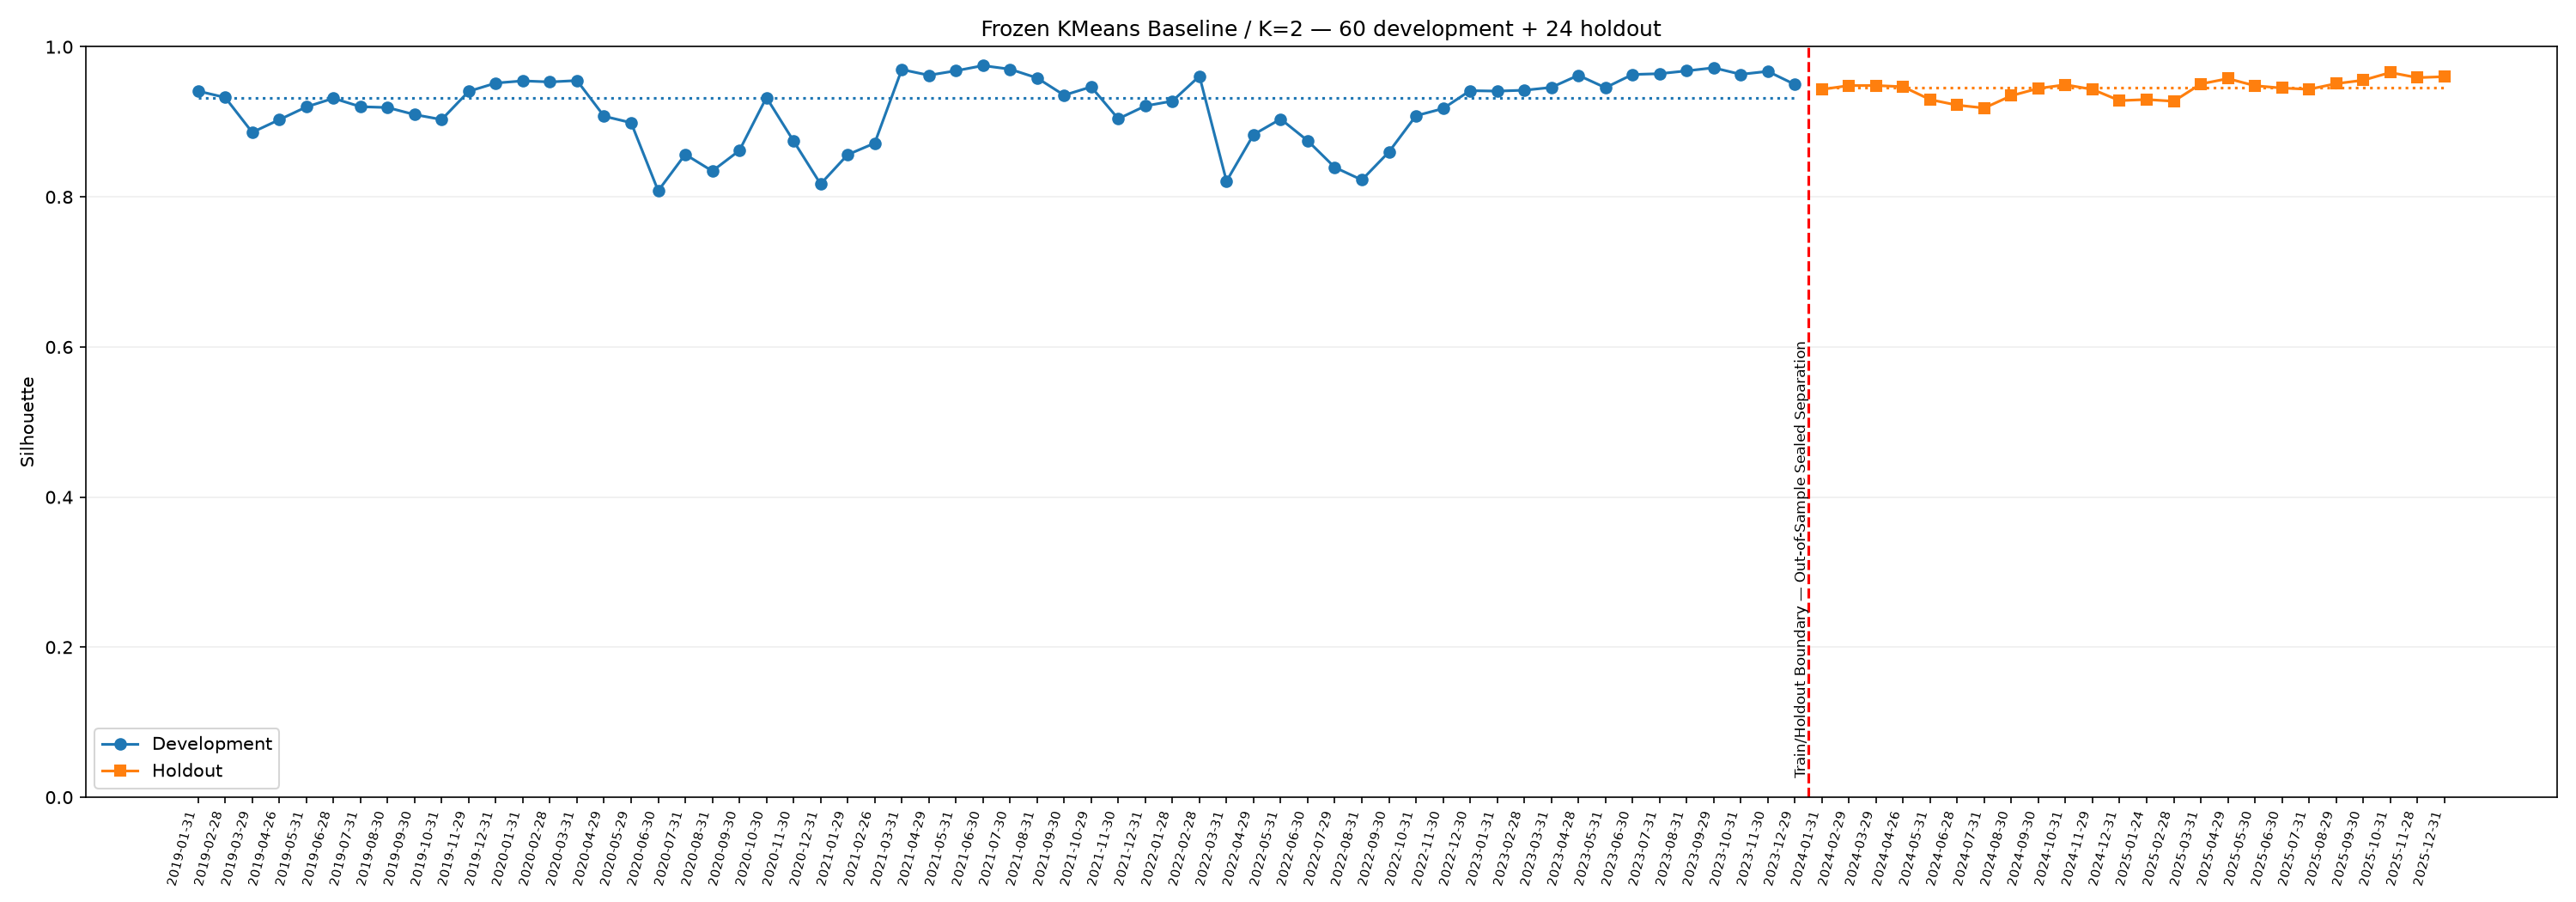

# Báo cáo Nhiệm vụ 11 — Final Holdout V2

## A — Cổng đóng băng và thực thi
KMeans Baseline, sklearn, K=2; seed=42, n_init=10, max_iter=300.
Decision: 2026-10-21T16:42:25+00:00; mở holdout: 2026-10-21T17:31:03.218171+00:00.
Nguồn: `CAFEF_C8_COMPLETE_ONLY_V2`, feature version 1.6.0; source hash
`414ed8102b1b18039eb35aa07615d55353941b641feeea60106fb3d120cac131`. Input/config/code được khóa trong manifest.
Chạy 24/24 snapshot; skip 0; 28110 assignments;
23/23 cặp nội bộ holdout. Robust Scaling và fit độc lập mỗi tháng,
ngưỡng universe 100, không quét K hoặc chạy comparator. Nhãn bắt đầu chuỗi mới tại
ranh giới Dev/Holdout; không nối qua skip hoặc khoảng trống tháng.

## B — Development so với Holdout
| Metric | Median Development | Median Holdout | Holdout − Development |
| --- | --- | --- | --- |
| silhouette | 0.931935 | 0.945927 | +0.013992 |
| davies_bouldin | 0.396416 | 0.399988 | +0.003572 |
| calinski_harabasz | 1122.325007 | 3191.392380 | +2069.067373 |
| inertia | 82143.837336 | 1290877.594618 | +1208733.757282 |
| cluster_balance | 0.023814 | 0.024941 | +0.001128 |
| ari | 0.768741 | 0.849616 | +0.080874 |
| nmi | 0.624996 | 0.723712 | +0.098715 |
| persistence_probability | 0.989313 | 0.993590 | +0.004277 |
| migration_rate | 0.010687 | 0.006410 | -0.004277 |

Delta Silhouette thực tế: **+0.013992**.
Đọc kết quả cùng Balance, quy mô cụm nhỏ, ARI và biến động universe. Rubric trong
kế hoạch không tự chứng minh không overfit, macro regime shift hay lợi ích đầu tư.

![Quỹ đạo 84 mốc](../artifacts/m2-final-holdout-v2/holdout_vs_dev_trajectory.png)

## C — Hồ sơ và giới hạn
`profile_consistency.csv` so tám feature gốc qua mean hồ sơ tháng, xếp vai trò
Higher/Lower mom_63 riêng từng tháng; không giả định nhãn C0/C1 có cùng ý nghĩa
qua ranh giới. Cụm nhỏ nhất holdout: 22 mã.

| Feature | Higher mom63 Dev mean | Higher mom63 Holdout mean | Lower mom63 Dev mean | Lower mom63 Holdout mean |
| --- | --- | --- | --- | --- |
| mom_21 | 0.046239 | 0.036617 | 0.011683 | 0.011783 |
| mom_63 | 0.267779 | 0.131048 | 0.037829 | 0.034560 |
| mom_126 | 0.483932 | 0.182279 | 0.127664 | 0.109478 |
| mom_252 | 0.625512 | 0.295601 | 0.286994 | 0.242701 |
| vol_63 | 0.471170 | 0.390745 | 0.493977 | 0.402170 |
| mdd_126 | -0.270279 | -0.212414 | -0.283261 | -0.213341 |
| beta_126 | 1.085649 | 0.860597 | 0.681168 | 0.769899 |
| liquidity_21 (tỷ VND/phiên) | 169.392821 | 331.659360 | 85.747618 | 160.445105 |

Các Mean trên là tổng hợp không trọng số qua hồ sơ tháng, không phải median cổ phiếu.
Giữ mô tả trung tính; không mặc định nhóm momentum cao phải có thanh khoản lớn.
Migration chỉ tính mã chung, không phải turnover/chi phí danh mục. Không suy nguyên
nhân VN-Index khi chưa có phân tích chỉ số; không retune từ kết quả holdout.
Đây là monthly independent clustering market-only, không phải Dynamic Clustering.
Lần chạy sau chỉ verify checksum/nạp lại, không refit. Task 12/M3 thực hiện riêng.


TASK 11 VERIFIED: KMeans_Baseline | snapshots: 24 | temporal pairs: 23


,snapshot_date,mom_21,mom_63,mom_126,mom_252,vol_63,mdd_126,beta_126,liquidity_21
0,2024-01-31,6.117485e-07,6.175343e-06,1.066324e-06,3.418176e-06,1.520745e-06,6.925765e-09,0.000017,0.999970
1,2024-02-29,1.506788e-06,2.357724e-06,1.087491e-06,5.214651e-06,1.395457e-06,3.453391e-08,0.000014,0.999974
2,2024-03-29,5.211195e-09,8.870559e-07,6.600423e-07,2.938600e-06,8.731784e-07,1.005102e-07,0.000009,0.999985
3,2024-04-26,1.449636e-06,2.974556e-09,5.919586e-07,2.690109e-06,6.506248e-07,4.744867e-07,0.000010,0.999984
4,2024-05-31,1.378686e-07,9.516471e-08,2.026026e-06,9.354310e-06,2.490050e-06,1.888949e-06,0.000032,0.999952
5,2024-06-28,3.449243e-06,1.706497e-06,3.631313e-07,4.973587e-06,6.935933e-06,4.740028e-06,0.000050,0.999928
6,2024-07-31,3.820376e-06,1.006722e-06,1.246714e-07,5.112133e-07,8.143773e-06,1.903142e-06,0.000044,0.999940
7,2024-08-30,5.275261e-06,8.532841e-07,1.850704e-06,8.369339e-08,3.424773e-06,5.671897e-07,0.000010,0.999977
8,2024-09-30,1.082202e-06,1.142166e-06,6.850504e-07,1.251254e-07,2.713110e-06,7.337313e-07,0.000008,0.999985
9,2024-10-31,2.540015e-07,3.139465e-06,4.790678e-09,9.879479e-07,1.453639e-06,1.557539e-06,0.000004,0.999989


## Diễn giải kết quả thực tế

Silhouette Holdout **0.9459**, chênh lệch **+0.0140**;
ARI median **0.8496**.

Cụm nhỏ mỗi tháng có **22–41 mã**, Balance median
**0.0249** so với **0.0238** ở Development.

Thanh khoản đóng góp median **99.9974%** vào bình phương khoảng cách
hai centroid trong không gian Robust Scaling. Đây là phép phân rã khoảng cách,
không phải tỷ lệ lợi nhuận, explained variance hoặc chứng minh nguyên nhân về mặt cơ chế.

Tỷ lệ trên chỉ phân rã khoảng cách trong mẫu đã chạy, không tự xác nhận cơ chế dòng tiền.
Đọc cùng Balance và quy mô cụm nhỏ, không tự gán nhãn đầu tư hoặc nguyên nhân thị trường.
Không retune phương pháp đã khóa bằng kết quả Holdout.


In [8]:
display(Image(filename=str(target / 'holdout_vs_dev_trajectory.png')))
verified_target, verified_manifest = run_final_holdout(ROOT)
assert verified_target == target and verified_manifest == manifest
report_path = REPORT_PATH
display(Markdown(report_path.read_text(encoding='utf-8')))
print('TASK 11 VERIFIED:', manifest['selected_method'],
      '| snapshots:', manifest['n_snapshots'], '| temporal pairs:', manifest['n_temporal_pairs'])

# Independent geometric interpretation from saved centroids; no new fit.
import numpy as np
separation_rows = []
for path in sorted(MODEL_DIR.glob('????-??-??.json')):
    model = read_json(path)
    squared = (np.array(model['centroids'][0]) - np.array(model['centroids'][1])) ** 2
    share = squared / squared.sum()
    separation_rows.append(dict(snapshot_date=path.stem,
        **dict(zip(model['config']['features'], share.tolist()))))
separation = pd.DataFrame(separation_rows)
display(separation)
liq_share = separation.liquidity_21.median()
balance = gap.set_index('metric').loc['cluster_balance']
minimum = int(profiles['size'].min())
maximum_small = int(profiles.groupby('snapshot_date')['size'].min().max())
display(Markdown(f"""## Diễn giải kết quả thực tế

Silhouette Holdout **{sil.holdout_median:.4f}**, chênh lệch **{sil.delta_holdout_minus_development:+.4f}**;
ARI median **{gap.set_index('metric').loc['ari', 'holdout_median']:.4f}**.

Cụm nhỏ mỗi tháng có **{minimum}–{maximum_small} mã**, Balance median
**{balance.holdout_median:.4f}** so với **{balance.development_median:.4f}** ở Development.

Thanh khoản đóng góp median **{liq_share:.4%}** vào bình phương khoảng cách
hai centroid trong không gian Robust Scaling. Đây là phép phân rã khoảng cách,
không phải tỷ lệ lợi nhuận, explained variance hoặc chứng minh nguyên nhân về mặt cơ chế.

Tỷ lệ trên chỉ phân rã khoảng cách trong mẫu đã chạy, không tự xác nhận cơ chế dòng tiền.
Đọc cùng Balance và quy mô cụm nhỏ, không tự gán nhãn đầu tư hoặc nguyên nhân thị trường.
Không retune phương pháp đã khóa bằng kết quả Holdout.
"""))